In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
sys.path.append(base_path)

import tensorflow as tf
from tensorflow.keras.callbacks import TensorBoard

import numpy as np
from tqdm import tqdm
import datetime

from data_loaders.data_loader_complete import DataLoaderComplete
import project_images_loader as pil
import matplotlib.pyplot as plt
from layers.Wavelet3D import DWT3D

import discriminator as Discriminator
import generator as Generator

import utils.functions as fc
import utils.visualization as vis
import utils.util_deep_learning as udl
import utils.util as util





TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

Tensorflow Addons supports using Python ops for all Tensorflow versions above or equal to 2.12.0 and strictly below 2.15.0 (nightly versions are not supported). 
 The versions of TensorFlow you are currently using is 2.10.1 and is not supported. 
Some things might work, some things might not.
If you were to encounter a bug, do not file an issue.
If you want to make sure you're using a tested and supported configuration, either change the TensorFlow version or the TensorFlow Addons's version. 
You can find the compatibility matrix in TensorFlow Addon's readme:
https://github.com/tensorflow/

## Visualize data

In [2]:
    
# %matplotlib widget

# data_train = DataLoader(batch_size=3, image_size=(193,229,193), shuffle=False, channels_first=False, image_sufix=pil.INAME_PREPROCESSED, nb_patients=-1, server=True)
# # fc.imgshow_3D("", data_train[0][0][0,0])
# fc.imgshow_3D("", data_train[0][0][0,...,0])

### Validation visualization

In [3]:
def show_generated_image(id, G, img_size, current_plane=116):
    def fast_resieze(img, img_size):
        return img[:img_size[0], :img_size[1], :img_size[2]]
    
    img_hunt3 = fast_resieze(pil.load_preprocessed_image(3, id, absolute=True)[0], img_size)
    img_hunt4 = fast_resieze(pil.load_preprocessed_image(4, id, absolute=True)[0], img_size)

    img_gen_h4 = G(np.expand_dims(np.expand_dims(img_hunt3, axis=0), axis=-1), training=False)
    img_gen_h4 = img_gen_h4[-1][0, ...,0].numpy()
    img_gen_h4[img_gen_h4 < 0] = 0
    img_gen_h4 = img_gen_h4 / np.max(img_gen_h4)
    vis.shows_3_images(img_hunt3, img_hunt4, img_gen_h4, current_plane=current_plane)



### Loss functions

In [4]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=False)


def adversarial_loss(disc_real, disc_fake):

    real_loss = cross_entropy(tf.ones_like(disc_real), disc_real)
    fake_loss = cross_entropy(tf.zeros_like(disc_fake), disc_fake)

    loss = real_loss  + fake_loss
    return loss

def quality_loss(target_image, predicted_image, disc_prob, beta=1.5):
    loss = tf.reduce_mean(tf.abs(target_image - predicted_image) * tf.pow(1 - disc_prob, beta))
    return loss

def gram_matrix(input_tensor):
    batch_size, width, height, deep, channels = input_tensor.get_shape().as_list()
    reshaped_tensor = tf.reshape(input_tensor, [batch_size, width * height, deep])
    gram_matrix = tf.matmul(reshaped_tensor, reshaped_tensor, transpose_a=True)
    num_elements = tf.cast(width * height * deep * channels, tf.float32)
    gram_matrix /= num_elements
    return gram_matrix


def texture_loss(target_image, predicted_image):
    gram_real = gram_matrix(target_image)
    gram_fake = gram_matrix(predicted_image)
    
    loss = tf.reduce_mean(tf.square(gram_real - gram_fake))
    
    return loss

dwt3D_layer = DWT3D(wavelet_name="bior1.3")
def frequency_loss(target_image, predicted_image):
    dwt_target_image = dwt3D_layer(target_image)
    dwt_predicted_image = dwt3D_layer(predicted_image)
    loss = tf.reduce_mean(tf.abs(dwt_target_image - dwt_predicted_image))
    return loss


In [5]:
@tf.function
def train_step(G, D, h3_batch, h4_batch, g_optimizer, d_optimizer):
    with tf.GradientTape() as g_h4_tape, tf.GradientTape() as d_h4_tape:
        h4_fake1, h4_fake2, h4_fake3  = G(h3_batch, training=True)

        disc_h4_real1, disc_h4_real2, disc_h4_real3 = D(h4_batch, training=True)
        disc_h4_fake1, disc_h4_fake2, disc_h4_fake3 = D(h4_fake3, training=True)


        # obtain reduced batches
        h4_batch_2 = tf.nn.pool(h4_batch, window_shape=(2, 2, 2), pooling_type='AVG', strides=(2, 2, 2), padding='VALID')
        h4_batch_1 = tf.nn.pool(h4_batch_2, window_shape=(2, 2, 2), pooling_type='AVG', strides=(2, 2, 2), padding='VALID')
        

        # ---- Adversarial loss
        ls1_adv = adversarial_loss(disc_h4_real1, disc_h4_fake1)
        ls2_adv = adversarial_loss(disc_h4_real2, disc_h4_fake2)
        ls3_adv = adversarial_loss(disc_h4_real3, disc_h4_fake3)

        # ---- Paired loss
        # Quality loss
        ls1_qa_g_h4 = quality_loss(h4_batch_1, h4_fake1, disc_h4_fake1)
        ls2_qa_g_h4 = quality_loss(h4_batch_2, h4_fake2, disc_h4_fake2)
        ls3_qa_g_h4 = quality_loss(h4_batch, h4_fake3, disc_h4_fake3)

        # Texture loss
        ls1_tex_g_h4 = texture_loss(h4_batch_1, h4_fake1)
        ls2_tex_g_h4 = texture_loss(h4_batch_2, h4_fake2)
        ls3_tex_g_h4 = texture_loss(h4_batch, h4_fake3)

        # Frequency loss
        ls1_freq_g_h4 = frequency_loss(h4_batch_1, h4_fake1)
        ls2_freq_g_h4 = frequency_loss(h4_batch_2, h4_fake2)
        ls3_freq_g_h4 = frequency_loss(h4_batch, h4_fake3)

        # ---- Cycle consistency loss

        # ---- Total loss
        ls1_g_h4 = ls1_adv + ls1_qa_g_h4 + ls1_tex_g_h4 + ls1_freq_g_h4 
        ls2_g_h4 = ls2_adv + ls2_qa_g_h4 + ls2_tex_g_h4 + ls2_freq_g_h4 
        ls3_g_h4 = ls3_adv + ls3_qa_g_h4 + ls3_tex_g_h4 + ls3_freq_g_h4 

   
        # ---- generator losses
        g_loss = ls1_g_h4 + ls2_g_h4 + ls3_g_h4

        # ---- discriminator losses
        d_loss = ls1_adv + ls2_adv + ls3_adv


    g_h4_gradients = g_h4_tape.gradient(g_loss, G.trainable_variables)

    d_h4_gradients = d_h4_tape.gradient(d_loss, D.trainable_variables)

    g_optimizer.apply_gradients(zip(g_h4_gradients, G.trainable_variables))
    d_optimizer.apply_gradients(zip(d_h4_gradients, D.trainable_variables))

    return d_loss, g_loss

### Training


Epoch 1/50


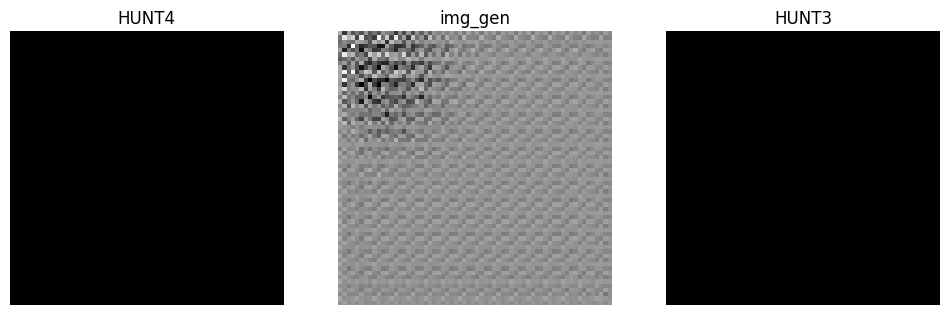

Initializing...:   0%|          | 0/300 [00:00<?, ?it/s]

In [6]:

def train(num_epochs, batch_size):
    # input_shape = (193,229,193)
    # input_shape = (192,224,192)
    input_shape = (64,64,64)

    # ---- Models
    D = Discriminator.MetamorphicDiscriminator()
    G = Generator.MetamorphicGenerator()

    # optimizers
    inital_lr = 1e-4
    g_optimizer = tf.keras.optimizers.Adam(inital_lr)
    d_optimizer = tf.keras.optimizers.Adam(inital_lr)

    # ---- Data
    server = False
    data_train = DataLoaderComplete(image_sufix=pil.INAME_PREPROCESSED,
                                    batch_size=batch_size, 
                                    image_size=input_shape, 
                                    channels_first=False,
                                    shuffle=True, 
                                    nb_patients=300, 
                                    shuffle_before_selecting=False, 
                                    server=server)
    # visualization
    nb_loss = 2
    acum_loss_train = udl.AcumulativeMetrics(nb_metrics = nb_loss)
    # tensorboard_callback = TensorBoard(log_dir=f"{current_path}/models/logs")

    log_dir=f"{current_path}/models/logs/"
    summary_writer = tf.summary.create_file_writer(
    log_dir + "fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))
    # %load_ext tensorboard
    # %tensorboard --logdir {log_dir}

    # ---- checkpoint
    checkpoint_dir = f"{current_path}/models/training_checkpoints/"
    checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
    checkpoint = tf.train.Checkpoint(generator_optimizer=g_optimizer,
                                    discriminator_optimizer=d_optimizer,
                                    generator=G,
                                    discriminator=D)
    # checkpoint_manager = tf.train.CheckpointManager(checkpoint, checkpoint_dir)
    # restore checkpoint
    checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))

    for epoch in range(0,num_epochs):

        print(f"\nEpoch {epoch+1}/{num_epochs}")
        
        # visualize images
        show_generated_image("08202", G, input_shape, current_plane=32)

        # ---- Train
        acum_loss_train.reset()
        progress_bar = tqdm(total=len(data_train), desc=f'Initializing...')
        for step, (x_batch, y_batch) in enumerate(data_train):
            d_loss, g_loss = train_step(G, D, x_batch, y_batch, g_optimizer, d_optimizer)
            acum_loss_train.update((d_loss, g_loss))
            loss_mean = acum_loss_train.get_mean()
            
            progress_bar.set_description(desc=f'd_loss: {loss_mean[0]:.5f} \t g_loss: {loss_mean[1]:.5f}')
            progress_bar.update(1)
        del progress_bar

        # ---- Check points
        if  epoch > 0 and epoch % 2 == 0:
            checkpoint.save(file_prefix=checkpoint_prefix)
        
        # ---- Learning rate
        # if epoch > 44 and epoch % 22 == 0:
        if epoch > 44 and epoch % 22 == 0:
            inital_lr *= 0.5
            g_optimizer.learning_rate = inital_lr
            d_optimizer.learning_rate = inital_lr

        # ---- tensorboard
        loss_mean = acum_loss_train.get_mean()
        with summary_writer.as_default():
            tf.summary.scalar('d_loss', loss_mean[0], step=epoch)
            tf.summary.scalar('g_loss', loss_mean[1], step=epoch)


train(num_epochs=50, batch_size=1)

In [ ]:
# Sim: 0.00000 	 gen_loss: 0.93415 	 disc_loss: 1.11709: 100%|██████████| 8/8 [00:14<00:00,  1.86s/it]
# Sim: 0.00000 	 gen_loss: 1.22538 	 disc_loss: 1.64933: 100%|██████████| 8/8 [00:14<00:00,  1.86s/it]